# Домашнее задание

## Информация о кейсе

После отклика на вакансию показываем блок «Похожие вакансии»: 3–5 вакансий,
на которые можно откликнуться в один клик. Гипотеза продакта: соискатель
откликнется на большее число подходящих вакансий, и релевантных откликов
станет больше. Релевантный отклик — это отклик, после которого работодатель
пригласил соискателя или посмотрел контакты в его резюме. Приглашения
входят в релевантные отклики, релевантные входят в отклики.

• Фича окупается при росте релевантных откликов на соискателя минимум
на 1.7%. Если приглашения на соискателя упадут больше чем на 3%, фичу не
раскатываем.

• Блок виден только после отклика. Аудитории хватает, чтобы разделить всех
соискателей пополам.

• Тест пойдёт в следующем году: старт в понедельник 5 апреля 2027. Майские
праздники (1–3 и 8–10 мая) придутся на 4–5-ю неделю теста.

## Задание 1

1. Постановка. Сформулируйте гипотезу цепочкой «изменение → механизм
→ целевая метрика». Разложите метрики по корзинам (целевая, guardrail,
информационные), для включённых в тест укажите тип теста и 𝛼. Определите
единицу рандомизации, популяцию и trigger event.

#### Изменение
После отклика на вакансию показываем блок «Похожие вакансии»: 3–5 вакансий,
на которые можно откликнуться в один клик.

#### Механизм

Гипотеза продакта - cоискатель откликнется на большее число подходящих ваканский, и релевантный откликов станет больше.

Работодатели.
Отклинется на большее число ваканский всего → больше релевантных откликов всего? Если просто увеличивать количество отликов для каждого соискателя, то количество релевантных откликов увеличится? Если работодатель в пассивном поиске, то тогда он вероятнее встретить кандидата, который ему понравится и вероятнее его пригласит. Если работодатель в активном поиске, то он и так бы пригласил некоторое количество соискателей, чтобы закрыть место. У работодателя выбор соискателей станет больше - возможно, работодатели начнут приглашать больше, потому что будут иметь больше подходящих вариантов.

Соискатели.
Будут ли расти релевантные отклики от того, что в блоке будут более удачно подобраны вакансии похожие на эту? Мне кажется, что механизм рекомендаций уже смотрит на те вакансии, на которые человек откликнулся и предлагает их в выдаче, поэтому это вряд ли поменяет в таком плане. "на которые можно откликнуться в один клик" - это может повлиять на поведение соискателей. Они будут делать отклики немного импульсивнее и откликов станет больше? Возможное поведение сильно зависит от соискателя.

Интересует ли нас увеличение отликов всего? Из чего последует увеличение релевантных отликов?
Рост релевантных откликов из-за того, что вакансии более подходящие?

За релевантность откликов в основном отвечает работодатель, потому что он решает приглашать, брать контакт или нет. Эта фича изменяет функционал для соискателей, но влияет на поведение работодателей таким образом, что работодателям дается: больший выбор (если про количество), более подходящие кандидаты (если про качество).

Ввели блок → соискатели чаще откликаются на подходящие вакансии → больше релевантных откликов.

#### Метрики
- Целевая метрика - релевантные отклики на соискателя (должны вырасти хотя бы на 1.7%).
- Guardrail метрика - приглашения на соискателя (не должны упасть больше чем на 3%) - если релевантные отклики выросли, а приглашения упали, взаимодействие уходит с сайта.
- Guardrail метрика - возможно, просмотры вакансий на соискателя - не считаем просмотры с этого блока - если соискатель стал меньше смотреть вакансии тривиальным способом, то это плохо, потому что, во первых, зачем нам тогда основной продукт и система рекомендаций и фильтров, во вторых, потому что соискатель смотря только похожие вакансии видит более узчкую часть рынка.
- Информационнная метрика - количество отликов на соискателя (смотрим на увеличение)
- Информационная метрика - отношение релевантных откликов на отклики на соискателя (смотрим на качество)

#### Тест
- Релевантные отклики на соискателя - односторонний вверх. a = 0.05. (Потому что мы делаем выбор: раскатывать или нет, а не улучшать, менять или оставлять. Нас интересует только улучшение показателя)
- Приглашения на соискателя - одностронний вниз. a = 0.05.
- Количество откликов на соискателя - двусторонний. a = 0.001.
- Отношение релевантных откликов на отклики на соискателя - двусторонний. a = 0.001 

#### Единица рандомизации, популяция и Trigger event

Единица рандомизации - соискатель. Нельзя смешивать, например, по сессиям, потому что тогда контрольная и тестовая группы будут влиять друг на друга - это плохо. Можно соискатель х устройство, потому что, возможно, на пользователя не будет влиять отсутствие или присутствие фичи на разных устройствах - выигрыш в 2 раза, как будто можно, но не желательно.

Trigger event - первый отклик соискателя. 

Мы берем в анализ только тех, кто откликался на вакансии. Пользователей делим 50 на 50. 

## Задание 2
2. MDE по данным. Проверьте качество данных и выберите, какой период
истории подходит для прогноза. Для тестов длительностью 1–5 недель посчитайте MDE целевой метрики и guardrail по формуле из лекции (мощность
80%), опишите определение метрики на пользователя и популяцию, постройте
график. Объясните его форму.

### Данные

Загружаю два файла. `user_week_metrics` — это панель: одна строка на пользователя и неделю, в которую он заходил. Если в неделю не заходил, строки нет. `users` — справочник. В тесте участвуют соискатели, поэтому дальше оставляю только `APPLICANT`.

In [60]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import chisquare, norm, ttest_ind

pd.set_option("display.max_columns", 30)

metrics = pd.read_csv("data/user_week_metrics.csv", parse_dates=["week_start"])
users = pd.read_csv("data/users.csv", parse_dates=["reg_date"])

print("metrics:", metrics.shape)
print("users:", users.shape)
display(metrics.head())
display(users.head())

metrics: (870685, 10)
users: (388000, 6)


,week_start,user_id,user_type,vacancy_views_app,responses_app,relevant_responses_app,invitations_app,responses_emp,relevant_responses_emp,invitations_emp
0,2026-03-09,10000146,APPLICANT,16.0,1.0,1.0,0.0,NaN,NaN,NaN
1,2026-03-09,10000500,APPLICANT,16.0,2.0,1.0,0.0,NaN,NaN,NaN
2,2026-03-09,10001679,APPLICANT,60.0,14.0,9.0,0.0,NaN,NaN,NaN
3,2026-03-09,10002834,APPLICANT,23.0,8.0,4.0,0.0,NaN,NaN,NaN
4,2026-03-09,10003079,APPLICANT,46.0,3.0,2.0,1.0,NaN,NaN,NaN


,user_id,user_type,reg_date,region_group,platform,company_size
0,57423229,APPLICANT,2020-08-19,Города-миллионники,mobile_web,NaN
1,93238947,APPLICANT,2024-04-09,Москва и СПб,desktop,NaN
2,82066772,APPLICANT,2026-02-08,Города-миллионники,app,NaN
3,31583398,APPLICANT,2025-08-15,Москва и СПб,desktop,NaN
4,46764711,APPLICANT,2024-08-21,Остальные,desktop,NaN


### Проверка

In [61]:
app = metrics[metrics["user_type"] == "APPLICANT"].copy()

print("Дубли (week_start, user_id):", metrics.duplicated(["week_start", "user_id"]).sum())
print("Отрицательные значения у соискателей:")
print((app[["vacancy_views_app", "responses_app", "relevant_responses_app", "invitations_app"]] < 0).sum())

print("\nВложенность у соискателей:")
print("relevant > responses:", (app["relevant_responses_app"] > app["responses_app"]).sum())
print("invitations > relevant:", (app["invitations_app"] > app["relevant_responses_app"]).sum())

print("\nПропуски responses_app по типу:")
print(metrics.groupby("user_type")["responses_app"].apply(lambda s: s.isna().sum()))
print("Пропуски responses_emp по типу:")
print(metrics.groupby("user_type")["responses_emp"].apply(lambda s: s.isna().sum()))

Дубли (week_start, user_id): 0
Отрицательные значения у соискателей:
vacancy_views_app         0
responses_app             0
relevant_responses_app    0
invitations_app           0
dtype: int64

Вложенность у соискателей:
relevant > responses: 0
invitations > relevant: 0

Пропуски responses_app по типу:
user_type
APPLICANT        0
EMPLOYER     47147
Name: responses_app, dtype: int64
Пропуски responses_emp по типу:
user_type
APPLICANT    823538
EMPLOYER          0
Name: responses_emp, dtype: int64


In [62]:
print("Дубли в users:", users["user_id"].duplicated().sum())
print("Пропуски в users:")
print(users.isna().sum())

print("\nСоискателей из метрик нет в users:", len(set(app["user_id"]) - set(users["user_id"])))

check = app[["user_id", "user_type"]].drop_duplicates().merge(
    users[["user_id", "user_type"]], on="user_id", suffixes=("_metrics", "_users")
)
print("Несовпадение user_type:", (check["user_type_metrics"] != check["user_type_users"]).sum())

Дубли в users: 0
Пропуски в users:
user_id              0
user_type            0
reg_date             0
region_group      8000
platform          8000
company_size    380000
dtype: int64

Соискателей из метрик нет в users: 0
Несовпадение user_type: 0


Данные чистые. Пропуски структурные: `region_group` и `platform` есть только у соискателей, `company_size` только у работодателей.

### Период

In [63]:
weekly = app.groupby("week_start").agg(
    users=("user_id", "nunique"),
    responders=("responses_app", lambda s: (s > 0).sum()),
    responses=("responses_app", "sum"),
    relevant=("relevant_responses_app", "sum"),
    invitations=("invitations_app", "sum"),
).reset_index()

weekly["responder_share"] = weekly["responders"] / weekly["users"]
weekly["relevant_per_user"] = weekly["relevant"] / weekly["users"]
weekly["invitations_per_user"] = weekly["invitations"] / weekly["users"]

display(weekly[["week_start", "users", "responders", "responder_share", "relevant_per_user", "invitations_per_user"]])

,week_start,users,responders,responder_share,relevant_per_user,invitations_per_user
0,2026-03-09,102701,94675,0.921851,2.690568,0.330435
1,2026-03-16,103872,95857,0.922838,2.669950,0.328828
2,2026-03-23,103090,95082,0.922320,2.701717,0.332030
3,2026-03-30,101859,93844,0.921313,2.695128,0.330977
4,2026-04-06,102791,94868,0.922921,2.691559,0.331478
5,2026-04-13,103926,95994,0.923676,2.723255,0.332641
6,2026-04-20,102599,94635,0.922377,2.681030,0.328736
7,2026-04-27,53178,34259,0.644233,2.667250,0.337640
8,2026-05-04,49522,31660,0.639312,2.575986,0.322443


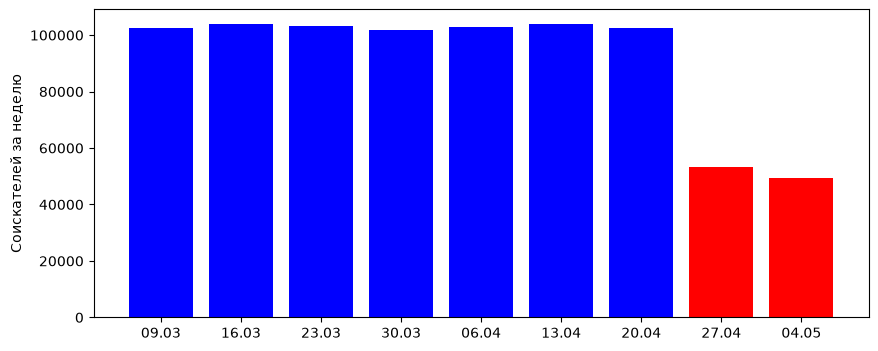

In [64]:
colors = ["red" if w >= pd.Timestamp("2026-04-27") else "blue" for w in weekly["week_start"]]

plt.figure(figsize=(10, 4))
plt.bar(weekly["week_start"].dt.strftime("%d.%m"), weekly["users"], color=colors)
plt.ylabel("Соискателей за неделю")
plt.show()

Последние две недели (27.04 и 04.05) выбиваются: активных соискателей сильно меньше, доля откликавшихся падает, но при этом релевантные отклики и приглашения на одного соискателя почти не меняются, то есть это в основном просто отток пользователей из-за праздников, а не изменение поведения.

Для прогноза подходят недели 9.03 - 26.04 (7 недель). Для графика MDE нужно 1-5 недель.


Считаю на одного соискателя, который откликался. В анализ попадают все, у кого за эти `k` недель был хотя бы один отклик. `n` на группу 50%, потому что разделяем пополам.

### MDE

`Δ = (z_0.95 + z_0.8) * sqrt(2) * σ / sqrt(n)`

`z_0.95 = 1.645`, `z_0.8 = 0.84`, итого `2.486`. Дальше `MDE% = Δ / mean * 100`.

a = 0.05, тест односторонний, мощность 80%. Считаю на первых 5 неделях: 9.03-12.04. 6-7 недели не беру, потому что 5 недель - максимальная длительность теста.


In [65]:
z = norm.ppf(0.95) + norm.ppf(0.8)

def mde_for(weeks):
    part = app[app["week_start"].isin(weeks)]
    per_user = part.groupby("user_id").agg(
        relevant=("relevant_responses_app", "sum"),
        invitations=("invitations_app", "sum"),
        responses=("responses_app", "sum"),
    )
    per_user = per_user[per_user["responses"] > 0]
    n = len(per_user) / 2

    row = {"недель": len(weeks), "n на группу": int(n)}
    for col, name in [("relevant", "рел."), ("invitations", "пригл.")]:
        mean = per_user[col].mean()
        std = per_user[col].std()
        mde = z * np.sqrt(2) * std / np.sqrt(n)
        row[f"{name} на соискателя"] = mean
        row[f"MDE {name}, %"] = mde / mean * 100
    return row

# первые 5 недель: 9.03-12.04
clean_weeks = sorted(app["week_start"].unique())[:5]
mde = pd.DataFrame([mde_for(clean_weeks[:k]) for k in range(1, 6)])
display(mde.round(2))


,недель,n на группу,рел. на соискателя,"MDE рел., %",пригл. на соискателя,"MDE пригл., %"
0,1,47337,2.92,1.75,0.36,3.90
1,2,78191,3.54,1.50,0.44,3.10
2,3,99173,4.20,1.41,0.52,2.76
3,4,114300,4.84,1.38,0.60,2.62
4,5,125810,5.50,1.37,0.68,2.53


По таблице видно, что целевая проходит уже на 2 неделях (1.50 < 1.7), а приглашения - только на 3. То есть длительность задаёт guardrail.

На графике две линии и бизнес пороги.

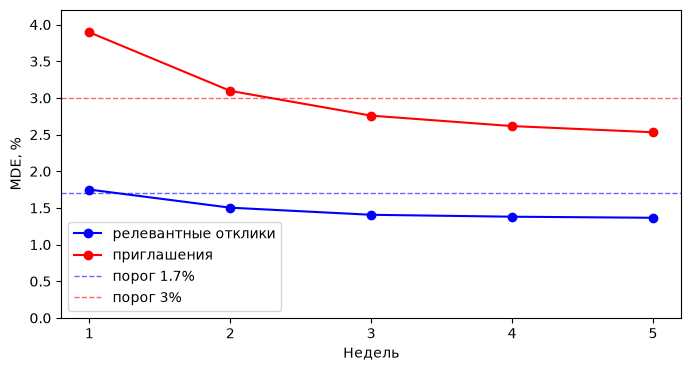

In [66]:
plt.figure(figsize=(8, 4))
plt.plot(mde["недель"], mde["MDE рел., %"], marker="o", color="blue", label="релевантные отклики")
plt.plot(mde["недель"], mde["MDE пригл., %"], marker="o", color="red", label="приглашения")
plt.axhline(1.7, color="blue", linestyle="--", linewidth=1, alpha=0.6, label="порог 1.7%")
plt.axhline(3.0, color="red", linestyle="--", linewidth=1, alpha=0.6, label="порог 3%")
plt.xticks(mde["недель"])
plt.ylim(0, 4.2)
plt.xlabel("Недель")
plt.ylabel("MDE, %")
plt.legend()
plt.show()


MDE падает нелинейно, потому что, во первых, n с неделями растет нелинейно, во вторых, потому что MDE падает, как `1/sqrt(n)`

## Задание 3
3. Длительность. Выберите срок эксперимента и обоснуйте: MDE и
бизнес-пороги, календарь, недельные циклы. Что вы скажете продакту: какой
эффект и какую просадку вы гарантированно заметите?

In [67]:
calendar_weeks = pd.date_range("2026-04-06", periods=5, freq="7D")

calendar_mde = pd.DataFrame([mde_for(calendar_weeks[:k]) for k in range(1, 6)])
display(calendar_mde.round(2))


,недель,n на группу,рел. на соискателя,"MDE рел., %",пригл. на соискателя,"MDE пригл., %"
0,1,47434,2.92,1.73,0.36,3.85
1,2,78165,3.58,1.51,0.44,3.08
2,3,98944,4.22,1.44,0.52,2.80
3,4,104265,4.68,1.59,0.58,2.91
4,5,108256,5.10,1.75,0.63,3.04


Беру 3 недели: 5.04 - 25.04.2027. На 3 неделях проходят оба порога: 1.44 < 1.7 и 2.80 < 3. На 4 неделях MDE хуже: 1.59 и 2.91, потому что добавляется 27.04 с праздниками. На 5 неделях добавляется еще 4.05, и обе метрики уже не проходят: 1.75 > 1.7 и 3.04 > 3.

3 недели - это минимальный срок, где проходят оба порога. В него попадают 3 полных недельных цикла и не попадают майские праздники.


### Продакту

За 3 недели с мощностью 80% заметим рост релевантных откликов от 1.44% и просадку приглашений от 2.80%. Это ниже порогов 1.7% и 3%, то есть тест чувствительнее, чем нужно для решения по фиче.


## Задание 4

4. Риски. Кратко по пунктам: пересечения с другими экспериментами, праздники,
мониторинг во время теста и условия остановки, срезы и множественные
сравнения.


### Риски

- Пересечение: параллельно может быть запущен другой эксперимент, который может повлиять на этот. Например, тот же поиск может повлиять на то, что люди будут чаще искать вакансии по фильтрам и поведение изменится.
- Праздники: тест идет 5-25.04.2027 и заканчивается до майских, поэтому праздники в него не попадают.
- Контекст времени: апрель 2027 может быть сезонно не таким, как апрель 2026.
- Мониторинг: если 𝑝SRM < 0.001 — стоп, что-то сломалось в рандомизации.
- Решение по целевой метрике принимаю только в конце, на промежуточные p-value не опираюсь.
- Срезы: заранее фиксирую 2-3 среза - платформа, регион, новые и опытные соискатели. Для срезов использовать поправку Холма, а информационные метрики и так смотрю на `α = 0.001`.


## Задание 5
5. A/A на истории. Многократно случайно разделите соискателей на две группы и
сравните их по целевой метрике за выбранный срок. Покажите долю запусков
с 𝑝 < 0.05 и проверьте SRM для одного из разбиений.

### A/A

Беру то же окно и ту же популяцию, что в MDE: 3 недели 6.04 - 26.04.2026 и соискатели, у которых за эти недели был хотя бы один отклик. Метрика - релевантные отклики на соискателя. Делаю 1000 разбиений: каждый соискатель независимо попадает в контроль или тест с вероятностью 0.5. Тест двусторонний: в A/A смотрю любые различия, а не только рост.


In [70]:
aa_weeks = pd.date_range("2026-04-06", periods=3, freq="7D")
aa_part = app[app["week_start"].isin(aa_weeks)]
aa_users = aa_part.groupby("user_id").agg(
    relevant=("relevant_responses_app", "sum"),
    responses=("responses_app", "sum"),
)
aa_users = aa_users[aa_users["responses"] > 0]
aa_values = aa_users["relevant"].to_numpy()

np.random.seed(2)

aa_pvals = []
aa_sizes = []

for _ in range(1000):
    group = np.random.binomial(1, 0.5, size=len(aa_values))
    control = aa_values[group == 0]
    treatment = aa_values[group == 1]
    aa_sizes.append((len(control), len(treatment)))
    aa_pvals.append(ttest_ind(treatment, control, equal_var=False).pvalue)

aa_pvals = np.array(aa_pvals)

print("Соискателей:", len(aa_values))
print("p < 0.05:", (aa_pvals < 0.05).sum(), "из", len(aa_pvals))
print("Доля:", round((aa_pvals < 0.05).mean() * 100, 1), "%")
print("Размеры групп:", aa_sizes[0])
print("SRM p-value:", round(chisquare(aa_sizes[0]).pvalue, 3))


Соискателей: 197889
p < 0.05: 46 из 1000
Доля: 4.6 %
Размеры групп: (99183, 98706)
SRM p-value: 0.284


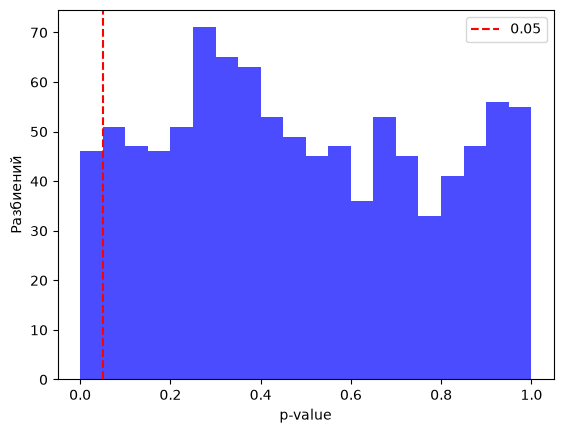

In [71]:
plt.hist(aa_pvals, bins=20, color="blue", alpha=0.7)
plt.axvline(0.05, color="red", linestyle="--", label="0.05")
plt.xlabel("p-value")
plt.ylabel("Разбиений")
plt.legend()
plt.show()


p < 0.05 в 46 случаях из 1000, это 4.6% - около 5%. Гистограмма p-value примерно ровная, у нуля всплеска нет. SRM p-value 0.284 > 0.001, группы почти одинаковые: 99 183 и 98 706. Значит, A/A не находит эффект там, где его нет.